In [37]:
!pip install nltk scikit-learn pandas matplotlib

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string

# Download required NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

print("All imports successful!")

All imports successful!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [39]:
data = {
    'ticket_text': [
        # Technical Issues - High Priority (10)
        "My account was hacked urgently need help immediately",
        "My laptop stopped working I lost all my data emergency",
        "I cannot login to my account urgent please help now",
        "The website is down urgently cannot place any orders",
        "My files got deleted after update need immediate help",
        "I am getting a black screen on startup urgent help needed",
        "My device keeps restarting by itself critical issue",
        "I cannot access my files after the update urgent",
        "The video call quality is very poor urgent meeting soon",
        "My microphone is not working on calls urgent help",

        # Technical Issues - Medium Priority (10)
        "The app keeps crashing on my device sometimes",
        "My internet connection keeps dropping occasionally",
        "I cannot reset my password please help when possible",
        "The screen on my phone is cracked need repair",
        "My printer is not connecting to my laptop",
        "The system keeps logging me out automatically",
        "My camera is not working on video calls",
        "The battery drains very fast on my device",
        "My keyboard stopped working suddenly",
        "I cannot download the software update",

        # Technical Issues - Low Priority (10)
        "The app is not loading any content no rush",
        "I cannot connect my device to bluetooth whenever possible",
        "The login page keeps refreshing itself minor issue",
        "My notifications are not working on the app low priority",
        "The system is running very slowly not urgent",
        "I cannot open any attachments in my email minor",
        "My microphone has minor static on calls no rush",
        "The video call background blur is not working",
        "I cannot find my saved files anywhere no rush",
        "The app theme is not changing minor issue",

        # Billing Issues - High Priority (8)
        "I was charged three times for my purchase urgent refund",
        "My payment was declined but money was deducted immediately",
        "I was charged after I cancelled my subscription urgent",
        "I am being charged for a service I never used urgent",
        "I was charged in the wrong currency high amount urgent",
        "My account shows unauthorized charges need urgent help",
        "I was charged for a cancelled order need immediate refund",
        "My credit card was charged without my permission urgent",

        # Billing Issues - Medium Priority (9)
        "I was billed the wrong amount please check",
        "Why is my bill higher than usual this month",
        "My discount code was not applied to my order",
        "Please explain the extra charges on my bill",
        "My promo code is not working at checkout",
        "I want a breakdown of my monthly charges",
        "My coupon was not applied properly",
        "I need to update my billing address",
        "I am being charged monthly instead of yearly",

        # Billing Issues - Low Priority (8)
        "I want to cancel my subscription no rush",
        "I want to upgrade my plan when convenient",
        "I need an invoice for my last payment no hurry",
        "I need a receipt for my recent purchase",
        "I want to downgrade my subscription plan",
        "I want to change my payment method when possible",
        "I need to change my subscription billing date no rush",
        "I want to know more about the premium plan",

        # Refund Issues - High Priority (8)
        "I have been waiting for refund for 3 months urgent",
        "I was promised a refund but never got it urgent help",
        "My refund was processed but never reached my account urgent",
        "I returned the product two weeks ago still no refund urgent",
        "The seller refused my return request urgent escalation needed",
        "I received a completely damaged product need urgent refund",
        "I never received my refund after multiple follow ups urgent",
        "My exchange request has been ignored for weeks urgent",

        # Refund Issues - Medium Priority (9)
        "I want to return my headphones they are broken",
        "I received a damaged product and want a refund",
        "The item I received is not what I ordered",
        "I want to exchange my product for a different size",
        "The refund amount I received was wrong",
        "I want to return an item I bought by mistake",
        "The product quality is very poor I want a refund",
        "I want to return my order it does not fit",
        "I received an incomplete order and want a refund",

        # Refund Issues - Low Priority (8)
        "I need to return a gift I received no rush",
        "I returned the wrong item by mistake low priority",
        "I want to return a duplicate item I received",
        "The refund policy was not explained to me clearly",
        "I want to return a subscription box I received",
        "My return label is not working minor issue",
        "I need to return an item that arrived late no rush",
        "I just want to know the return policy",

        # Shipping Issues - High Priority (8)
        "My order says delivered but I never got it urgent",
        "My order is showing as lost in transit urgent help",
        "My package was delivered to completely wrong address urgent",
        "I received someone else package urgent mix up",
        "My order has been stuck in transit for 3 weeks urgent",
        "My package was returned to sender by mistake urgent",
        "I received only part of my order urgent missing items",
        "My order arrived severely damaged urgent replacement needed",

        # Shipping Issues - Medium Priority (7)
        "Where is my order it has been 2 weeks",
        "My delivery driver left package in wrong place",
        "The estimated delivery date keeps changing",
        "My order was split into two shipments",
        "The tracking number is not working for my order",
        "I was not home when delivery was attempted",
        "My order arrived damaged need replacement",

        # Shipping Issues - Low Priority (5)
        "I need to change my delivery address no rush",
        "Can I change my order to express shipping",
        "I need to reschedule my delivery whenever possible",
        "I need to pick up my package from the depot",
        "The shipping address on my order is wrong minor fix",
    ],
    'category': [
        # Technical (30)
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        # Billing (25)
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        # Refund (25)
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        # Shipping (20)
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
    ],
    'priority': [
        # Technical priorities (30)
        'High','High','High','High','High',
        'High','High','High','High','High',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Low','Low','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Billing priorities (25)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Low','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Refund priorities (25)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Medium','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Shipping priorities (20)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Low','Low','Low','Low','Low',
    ]
}

df = pd.DataFrame(data)
print("Improved dataset created successfully!")
print("Shape:", df.shape)
print()
print("Category counts:")
print(df['category'].value_counts())
print()
print("Priority counts:")
print(df['priority'].value_counts())

Improved dataset created successfully!
Shape: (100, 3)

Category counts:
category
Technical    30
Billing      25
Refund       25
Shipping     20
Name: count, dtype: int64

Priority counts:
priority
High      34
Medium    34
Low       32
Name: count, dtype: int64


In [40]:
print("Categories in our dataset:")
print(df['category'].value_counts())
print()
print("Priority levels in our dataset:")
print(df['priority'].value_counts())

Categories in our dataset:
category
Technical    30
Billing      25
Refund       25
Shipping     20
Name: count, dtype: int64

Priority levels in our dataset:
priority
High      34
Medium    34
Low       32
Name: count, dtype: int64


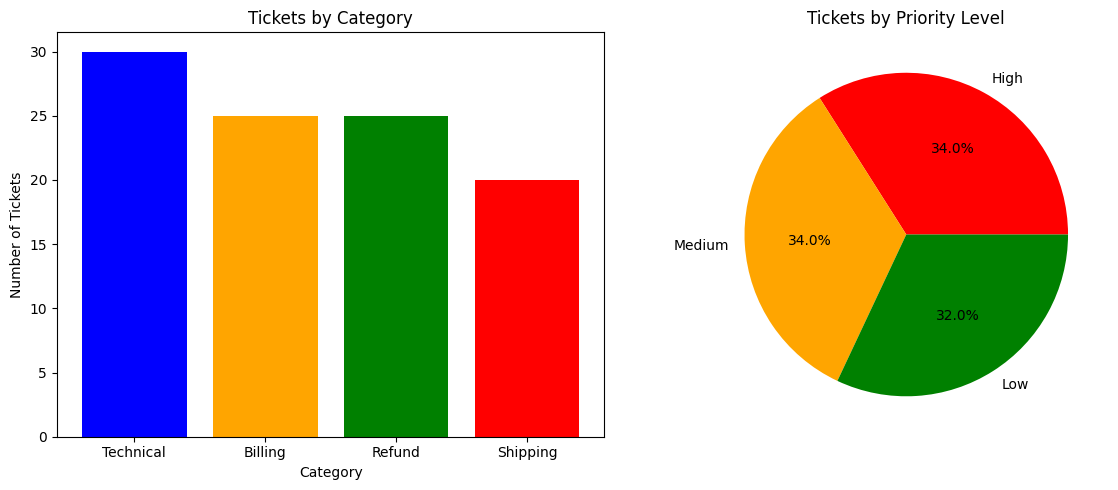

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1 - Tickets by Category
category_counts = df['category'].value_counts()
ax1.bar(category_counts.index, category_counts.values,
        color=['blue', 'orange', 'green', 'red'])
ax1.set_title('Tickets by Category')
ax1.set_xlabel('Category')
ax1.set_ylabel('Number of Tickets')

# Chart 2 - Tickets by Priority
priority_counts = df['priority'].value_counts()
ax2.pie(priority_counts.values, labels=priority_counts.index,
        autopct='%1.1f%%', colors=['red', 'orange', 'green'])
ax2.set_title('Tickets by Priority Level')

plt.tight_layout()
plt.show()

In [42]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # Step 1: Make lowercase
    text = text.lower()

    # Step 2: Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Step 3: Split into individual words
    words = word_tokenize(text)

    # Step 4: Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Step 5: Join back into a sentence
    return ' '.join(words)

# Apply cleaning to every ticket
df['cleaned_text'] = df['ticket_text'].apply(clean_text)

print("Text cleaning done!")
print()
print("Original:", df['ticket_text'][0])
print("Cleaned: ", df['cleaned_text'][0])

Text cleaning done!

Original: My account was hacked urgently need help immediately
Cleaned:  account hacked urgently need help immediately


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['cleaned_text'])

print("Text converted to numbers successfully!")
print("Shape:", X.shape)


Text converted to numbers successfully!
Shape: (100, 230)


In [44]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Our inputs and output
y_category = df['category']

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_category, test_size=0.2, random_state=42
)

# Build and train the model
category_model = MultinomialNB()
category_model.fit(X_train, y_train)

# Test it
y_pred = category_model.predict(X_test)

print("Category Classification Results:")
print(classification_report(y_test, y_pred))

Category Classification Results:
              precision    recall  f1-score   support

     Billing       1.00      0.57      0.73         7
      Refund       0.50      0.75      0.60         4
    Shipping       0.00      0.00      0.00         3
   Technical       0.67      1.00      0.80         6

    accuracy                           0.65        20
   macro avg       0.54      0.58      0.53        20
weighted avg       0.65      0.65      0.61        20



In [45]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Our inputs and output
y_category = df['category']

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_category, test_size=0.2, random_state=42
)

# Build and train the model
category_model = MultinomialNB()
category_model.fit(X_train, y_train)

# Test it
y_pred = category_model.predict(X_test)

print("Category Classification Results:")
print(classification_report(y_test, y_pred, zero_division=0))

Category Classification Results:
              precision    recall  f1-score   support

     Billing       1.00      0.57      0.73         7
      Refund       0.50      0.75      0.60         4
    Shipping       0.00      0.00      0.00         3
   Technical       0.67      1.00      0.80         6

    accuracy                           0.65        20
   macro avg       0.54      0.58      0.53        20
weighted avg       0.65      0.65      0.61        20



In [46]:
y_priority = df['priority']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y_priority, test_size=0.2, random_state=42
)

priority_model = MultinomialNB()
priority_model.fit(X_train2, y_train2)

y_pred2 = priority_model.predict(X_test2)

print("Priority Classification Results:")
print(classification_report(y_test2, y_pred2, zero_division=0))

Priority Classification Results:
              precision    recall  f1-score   support

        High       0.75      0.86      0.80         7
         Low       0.57      0.80      0.67         5
      Medium       0.80      0.50      0.62         8

    accuracy                           0.70        20
   macro avg       0.71      0.72      0.69        20
weighted avg       0.73      0.70      0.69        20



In [47]:
def assign_priority(text):
    text = text.lower()

    if any(word in text for word in high_priority):
        return "High"
    elif any(word in text for word in medium_priority):
        return "Medium"
    elif any(word in text for word in low_priority):
        return "Low"
    else:
        return "Medium"

In [48]:
high_priority = [
    "urgent", "server down", "system crash", "payment failed",
    "security breach", "cannot login", "website down", "hacked",
    "lost all my data", "data loss", "deleted", "immediately", "critical"
]

medium_priority = [
    "bug", "error", "issue", "not working", "delay",
    "slow performance", "unexpected behavior", "glitch", "system lag"
]

low_priority = [
    "how", "what", "why", "can i", "is it", "help", "guide",
    "question", "support", "learn", "understand", "feature",
    "request", "suggestion", "feedback"
]

In [49]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [50]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [51]:
def test_low_detection():
    samples = [
        "feature request for dark mode",
        "how to reset password",
        "need guide for login",
        "just a suggestion for UI improvement"
    ]

    for s in samples:
        print(s, "→", assign_priority(s))

test_low_detection()

feature request for dark mode → Low
how to reset password → Low
need guide for login → Low
just a suggestion for UI improvement → Low


In [52]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [53]:
print(df.columns)

Index(['ticket_text', 'category', 'priority', 'cleaned_text'], dtype='object')


In [54]:
df["Priority"] = df["ticket_text"].apply(assign_priority)

print(df.head())

                                         ticket_text   category priority  \
0  My account was hacked urgently need help immed...  Technical     High   
1  My laptop stopped working I lost all my data e...  Technical     High   
2  I cannot login to my account urgent please hel...  Technical     High   
3  The website is down urgently cannot place any ...  Technical     High   
4  My files got deleted after update need immedia...  Technical     High   

                                    cleaned_text Priority  
0  account hacked urgently need help immediately     High  
1     laptop stopped working lost data emergency     High  
2               login account urgent please help     High  
3                  website urgently place orders     High  
4   files got deleted update need immediate help     High  


In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [56]:
X = df["ticket_text"]
y = df["Priority"]

In [57]:
vectorizer = TfidfVectorizer()

X_vectorized = vectorizer.fit_transform(X)

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

In [59]:
model = SVC(class_weight='balanced')

model.fit(X_train, y_train)

SVC(class_weight='balanced')

In [60]:
y_pred = model.predict(X_test)

In [61]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.85


In [62]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       0.00      0.00      0.00         2
      Medium       0.79      1.00      0.88        11

    accuracy                           0.85        20
   macro avg       0.60      0.62      0.60        20
weighted avg       0.78      0.85      0.81        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [63]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       0.00      0.00      0.00         2
      Medium       0.79      1.00      0.88        11

    accuracy                           0.85        20
   macro avg       0.60      0.62      0.60        20
weighted avg       0.78      0.85      0.81        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [64]:
new_ticket = ["Urgent! My account was hacked"]

new_ticket_vectorized = vectorizer.transform(new_ticket)

prediction = model.predict(new_ticket_vectorized)

print("Predicted Priority:", prediction[0])

Predicted Priority: High


In [65]:
"There is a small bug in the dashboard"

'There is a small bug in the dashboard'

In [66]:
new_ticket = ["There is a small bug in the dashboard"]

new_ticket_vectorized = vectorizer.transform(new_ticket)

prediction = model.predict(new_ticket_vectorized)

print("Predicted Priority:", prediction[0])

Predicted Priority: Medium


In [67]:
TfidfVectorizer(stop_words='english')

TfidfVectorizer(stop_words='english')

In [68]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       0.00      0.00      0.00         2
      Medium       0.79      1.00      0.88        11

    accuracy                           0.85        20
   macro avg       0.60      0.62      0.60        20
weighted avg       0.78      0.85      0.81        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [69]:
new_ticket

['There is a small bug in the dashboard']

In [70]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       0.00      0.00      0.00         2
      Medium       0.79      1.00      0.88        11

    accuracy                           0.85        20
   macro avg       0.60      0.62      0.60        20
weighted avg       0.78      0.85      0.81        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X_vectorized, y, test_size=0.2, random_state=42)

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

In [73]:
len(df)


100

In [74]:
print(X_train.shape)
print(X_test.shape)

(80, 281)
(20, 281)


In [75]:
print("Total dataset size:", X.shape[0])
print("Training size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Total dataset size: 100
Training size: 80
Test size: 20


In [76]:
!pip install seaborn

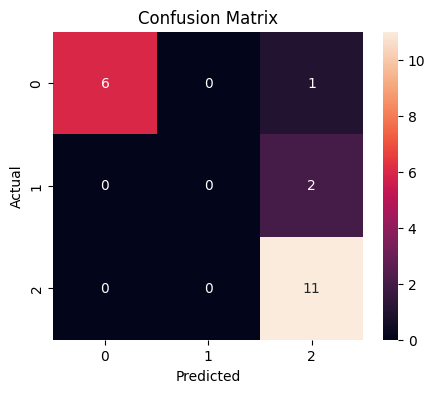

In [77]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [78]:
new_tickets = [
    "My account has been hacked urgently",
    "I need help resetting my password",
    "The website is down and not loading",
    "How do I change my profile picture?",
    "There is a small bug in the dashboard"
]

new_tickets_vectorized = vectorizer.transform(new_tickets)

predictions = model.predict(new_tickets_vectorized)

for ticket, pred in zip(new_tickets, predictions):
    print(ticket)
    print("Predicted Priority:", pred)
    print("-" * 50)

My account has been hacked urgently
Predicted Priority: High
--------------------------------------------------
I need help resetting my password
Predicted Priority: Medium
--------------------------------------------------
The website is down and not loading
Predicted Priority: Medium
--------------------------------------------------
How do I change my profile picture?
Predicted Priority: Medium
--------------------------------------------------
There is a small bug in the dashboard
Predicted Priority: Medium
--------------------------------------------------


In [79]:
import joblib

joblib.dump(model, "ticket_priority_model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")

print("Model saved successfully!")

Model saved successfully!


In [80]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [81]:
print(df["priority"].unique())

['High' 'Medium' 'Low']


In [82]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [83]:
df["priority"].value_counts(normalize=True)

,proportion
priority,
Medium,0.62
High,0.34
Low,0.04


In [84]:
test_cases = [
    "My account is hacked urgently",
    "How do I change my password?",
    "Can I update my profile picture?",
    "There is a minor visual issue on the dashboard",
    "The system is completely down"
]

test_vec = vectorizer.transform(test_cases)
preds = model.predict(test_vec)

for t, p in zip(test_cases, preds):
    print(t)
    print("Predicted:", p)
    print("-"*40)

My account is hacked urgently
Predicted: Medium
----------------------------------------
How do I change my password?
Predicted: Medium
----------------------------------------
Can I update my profile picture?
Predicted: Medium
----------------------------------------
There is a minor visual issue on the dashboard
Predicted: Medium
----------------------------------------
The system is completely down
Predicted: High
----------------------------------------


In [85]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2),
    min_df=2
)

In [86]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [87]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9
)

In [88]:
model = SVC(kernel='linear', class_weight='balanced')

In [89]:
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [90]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2),
    min_df=2
)

In [91]:
X = df["ticket_text"]
y = df["priority"]

X_vectorized = vectorizer.fit_transform(X)

In [92]:
data = {
    'ticket_text': [
        # Technical Issues - High Priority (10)
        "My account was hacked urgently need help immediately",
        "My laptop stopped working I lost all my data emergency",
        "I cannot login to my account urgent please help now",
        "The website is down urgently cannot place any orders",
        "My files got deleted after update need immediate help",
        "I am getting a black screen on startup urgent help needed",
        "My device keeps restarting by itself critical issue",
        "I cannot access my files after the update urgent",
        "The video call quality is very poor urgent meeting soon",
        "My microphone is not working on calls urgent help",

        # Technical Issues - Medium Priority (10)
        "The app keeps crashing on my device sometimes",
        "My internet connection keeps dropping occasionally",
        "I cannot reset my password please help when possible",
        "The screen on my phone is cracked need repair",
        "My printer is not connecting to my laptop",
        "The system keeps logging me out automatically",
        "My camera is not working on video calls",
        "The battery drains very fast on my device",
        "My keyboard stopped working suddenly",
        "I cannot download the software update",

        # Technical Issues - Low Priority (10)
        "The app is not loading any content no rush",
        "I cannot connect my device to bluetooth whenever possible",
        "The login page keeps refreshing itself minor issue",
        "My notifications are not working on the app low priority",
        "The system is running very slowly not urgent",
        "I cannot open any attachments in my email minor",
        "My microphone has minor static on calls no rush",
        "The video call background blur is not working",
        "I cannot find my saved files anywhere no rush",
        "The app theme is not changing minor issue",

        # Billing Issues - High Priority (8)
        "I was charged three times for my purchase urgent refund",
        "My payment was declined but money was deducted immediately",
        "I was charged after I cancelled my subscription urgent",
        "I am being charged for a service I never used urgent",
        "I was charged in the wrong currency high amount urgent",
        "My account shows unauthorized charges need urgent help",
        "I was charged for a cancelled order need immediate refund",
        "My credit card was charged without my permission urgent",

        # Billing Issues - Medium Priority (9)
        "I was billed the wrong amount please check",
        "Why is my bill higher than usual this month",
        "My discount code was not applied to my order",
        "Please explain the extra charges on my bill",
        "My promo code is not working at checkout",
        "I want a breakdown of my monthly charges",
        "My coupon was not applied properly",
        "I need to update my billing address",
        "I am being charged monthly instead of yearly",

        # Billing Issues - Low Priority (8)
        "I want to cancel my subscription no rush",
        "I want to upgrade my plan when convenient",
        "I need an invoice for my last payment no hurry",
        "I need a receipt for my recent purchase",
        "I want to downgrade my subscription plan",
        "I want to change my payment method when possible",
        "I need to change my subscription billing date no rush",
        "I want to know more about the premium plan",

        # Refund Issues - High Priority (8)
        "I have been waiting for refund for 3 months urgent",
        "I was promised a refund but never got it urgent help",
        "My refund was processed but never reached my account urgent",
        "I returned the product two weeks ago still no refund urgent",
        "The seller refused my return request urgent escalation needed",
        "I received a completely damaged product need urgent refund",
        "I never received my refund after multiple follow ups urgent",
        "My exchange request has been ignored for weeks urgent",

        # Refund Issues - Medium Priority (9)
        "I want to return my headphones they are broken",
        "I received a damaged product and want a refund",
        "The item I received is not what I ordered",
        "I want to exchange my product for a different size",
        "The refund amount I received was wrong",
        "I want to return an item I bought by mistake",
        "The product quality is very poor I want a refund",
        "I want to return my order it does not fit",
        "I received an incomplete order and want a refund",

        # Refund Issues - Low Priority (8)
        "I need to return a gift I received no rush",
        "I returned the wrong item by mistake low priority",
        "I want to return a duplicate item I received",
        "The refund policy was not explained to me clearly",
        "I want to return a subscription box I received",
        "My return label is not working minor issue",
        "I need to return an item that arrived late no rush",
        "I just want to know the return policy",

        # Shipping Issues - High Priority (8)
        "My order says delivered but I never got it urgent",
        "My order is showing as lost in transit urgent help",
        "My package was delivered to completely wrong address urgent",
        "I received someone else package urgent mix up",
        "My order has been stuck in transit for 3 weeks urgent",
        "My package was returned to sender by mistake urgent",
        "I received only part of my order urgent missing items",
        "My order arrived severely damaged urgent replacement needed",

        # Shipping Issues - Medium Priority (7)
        "Where is my order it has been 2 weeks",
        "My delivery driver left package in wrong place",
        "The estimated delivery date keeps changing",
        "My order was split into two shipments",
        "The tracking number is not working for my order",
        "I was not home when delivery was attempted",
        "My order arrived damaged need replacement",

        # Shipping Issues - Low Priority (5)
        "I need to change my delivery address no rush",
        "Can I change my order to express shipping",
        "I need to reschedule my delivery whenever possible",
        "I need to pick up my package from the depot",
        "The shipping address on my order is wrong minor fix",
    ],
    'category': [
        # Technical (30)
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        'Technical','Technical','Technical','Technical','Technical',
        # Billing (25)
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        'Billing','Billing','Billing','Billing','Billing',
        # Refund (25)
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        'Refund','Refund','Refund','Refund','Refund',
        # Shipping (20)
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
        'Shipping','Shipping','Shipping','Shipping','Shipping',
    ],
    'priority': [
        # Technical priorities (30)
        'High','High','High','High','High',
        'High','High','High','High','High',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Low','Low','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Billing priorities (25)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Low','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Refund priorities (25)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Medium','Medium','Low','Low','Low',
        'Low','Low','Low','Low','Low',
        # Shipping priorities (20)
        'High','High','High','High','High',
        'High','High','High','Medium','Medium',
        'Medium','Medium','Medium','Medium','Medium',
        'Low','Low','Low','Low','Low',
    ]
}

df = pd.DataFrame(data)
print("Improved dataset created successfully!")
print("Shape:", df.shape)
print()
print("Category counts:")
print(df['category'].value_counts())
print()
print("Priority counts:")
print(df['priority'].value_counts())

Improved dataset created successfully!
Shape: (100, 3)

Category counts:
category
Technical    30
Billing      25
Refund       25
Shipping     20
Name: count, dtype: int64

Priority counts:
priority
High      34
Medium    34
Low       32
Name: count, dtype: int64


In [93]:
X = df["ticket_text"]
y = df["priority"]

In [94]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

In [95]:
model = SVC(kernel='linear', class_weight='balanced')

model.fit(X_train, y_train)

SVC(class_weight='balanced', kernel='linear')

In [96]:
y_pred = model.predict(X_test)

In [97]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.75


In [98]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       0.50      0.60      0.55         5
      Medium       0.75      0.75      0.75         8

    accuracy                           0.75        20
   macro avg       0.75      0.74      0.74        20
weighted avg       0.78      0.75      0.76        20



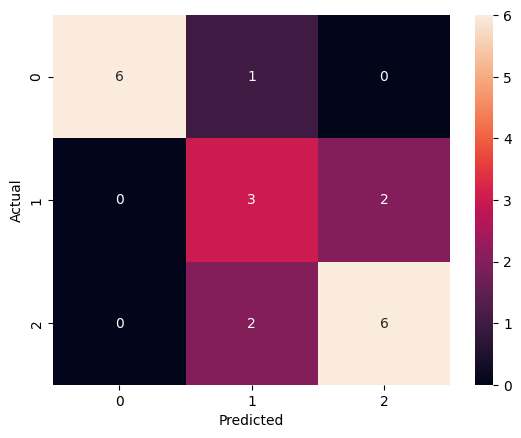

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [100]:
df["priority"].value_counts()

,count
priority,
High,34
Medium,34
Low,32


In [101]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [102]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [103]:
def assign_priority(text):
    text = text.lower()

    if any(word in text for word in high_priority):
        return "High"
    elif any(word in text for word in low_priority):
        return "Low"
    elif any(word in text for word in medium_priority):
        return "Medium"
    else:
        return "Low"

In [104]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [105]:
df["priority"].value_counts()

,count
priority,
Low,58
High,34
Medium,8


In [106]:
def assign_priority(text):
    text = text.lower()

    if any(word in text for word in high_priority):
        return "High"
    elif any(word in text for word in medium_priority):
        return "Medium"
    elif any(word in text for word in low_priority):
        return "Low"
    else:
        return "Medium"

In [107]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [108]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [109]:
def assign_priority(text):
    text = text.lower()

    # HIGH first (strong signals)
    if any(word in text for word in high_priority):
        return "High"

    # LOW second (very explicit intent signals)
    if any(word in text for word in low_priority):
        return "Low"

    # MEDIUM last (default system issues)
    if any(word in text for word in medium_priority):
        return "Medium"

    # fallback (safe default)
    return "Medium"

In [110]:
df["priority"] = df["ticket_text"].apply(assign_priority)

In [111]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [112]:
df["priority"].value_counts()

,count
priority,
Medium,62
High,34
Low,4


In [113]:
high_priority = [
    "urgent",
    "server down",
    "system crash",
    "payment failed",
    "security breach",
    "cannot login",
    "website down",
    "hacked",
    "lost all my data",
    "data loss",
    "deleted",
    "immediately",
    "critical"
]

medium_priority = [
    "bug",
    "error",
    "issue",
    "not working",
    "delay",
    "slow performance",
    "unexpected behavior",
    "glitch",
    "system lag"
]

low_priority = [
    "how",
    "what",
    "why",
    "can i",
    "is it",
    "help",
    "guide",
    "question",
    "support",
    "learn",
    "understand",
    "feature",
    "request",
    "suggestion",
    "feedback"
]

In [114]:
def assign_priority(text):
    text = text.lower()

    if any(word in text for word in high_priority):
        return "High"

    if any(word in text for word in medium_priority):
        return "Medium"

    if any(word in text for word in low_priority):
        return "Low"

    # fallback based on sentence intent
    if len(text.split()) <= 5:
        return "Low"
    else:
        return "Medium"

In [115]:
df["priority"] = df["ticket_text"].apply(assign_priority)
df["priority"].value_counts()

,count
priority,
Medium,61
High,34
Low,5


In [116]:
X = df["ticket_text"]
y = df["priority"]

X_vectorized = vectorizer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

model.fit(X_train, y_train)

SVC(class_weight='balanced', kernel='linear')

In [117]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.75
              precision    recall  f1-score   support

        High       1.00      0.71      0.83         7
         Low       0.00      0.00      0.00         3
      Medium       0.67      1.00      0.80        10

    accuracy                           0.75        20
   macro avg       0.56      0.57      0.54        20
weighted avg       0.68      0.75      0.69        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [118]:
model = SVC(class_weight='balanced')

In [119]:
from sklearn.utils import resample

low_df = df[df["priority"] == "Low"]
medium_df = df[df["priority"] == "Medium"]
high_df = df[df["priority"] == "High"]

low_upsampled = resample(low_df, replace=True, n_samples=20, random_state=42)

df_balanced = pd.concat([high_df, medium_df, low_upsampled])

In [120]:
X = df_balanced["ticket_text"]
y = df_balanced["priority"]

X_vectorized = vectorizer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.2,
    random_state=42
)

model.fit(X_train, y_train)

SVC(class_weight='balanced')

In [121]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8260869565217391
              precision    recall  f1-score   support

        High       1.00      0.57      0.73         7
         Low       1.00      0.75      0.86         4
      Medium       0.75      1.00      0.86        12

    accuracy                           0.83        23
   macro avg       0.92      0.77      0.81        23
weighted avg       0.87      0.83      0.82        23



In [122]:
import joblib

joblib.dump(model, "ticket_classifier_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [123]:
import joblib

joblib.dump(model, "ticket_classifier_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

[[ 4  0  3]
 [ 0  3  1]
 [ 0  0 12]]


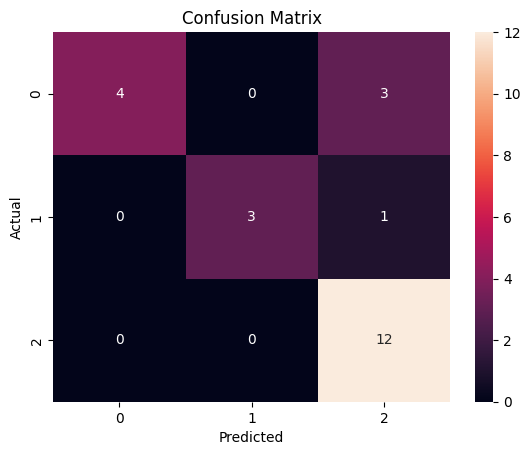

In [124]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [125]:
import joblib

joblib.dump(model, "ticket_classifier_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [126]:
print(model)
print(vectorizer)

SVC(class_weight='balanced')
TfidfVectorizer(min_df=2, ngram_range=(1, 2), stop_words='english')


In [127]:
import joblib

joblib.dump(model, "ticket_classifier_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Saved successfully")

Saved successfully


In [128]:
import os
print(os.listdir())

['.config', 'tfidf_vectorizer.pkl', 'ticket_classifier_model.pkl', 'ticket_priority_model.pkl', 'vectorizer.pkl', 'sample_data']


In [129]:
import joblib

model = joblib.load("ticket_classifier_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

def predict_ticket(text):
    X = vectorizer.transform([text])
    return model.predict(X)[0]

# test
print(predict_ticket("My internet is not working"))

Medium


In [130]:
import joblib

model = joblib.load("ticket_classifier_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

def predict_ticket(text):
    X = vectorizer.transform([text])
    return model.predict(X)[0]

print(predict_ticket("My internet is not working"))

Medium


[[ 4  0  3]
 [ 0  3  1]
 [ 0  0 12]]


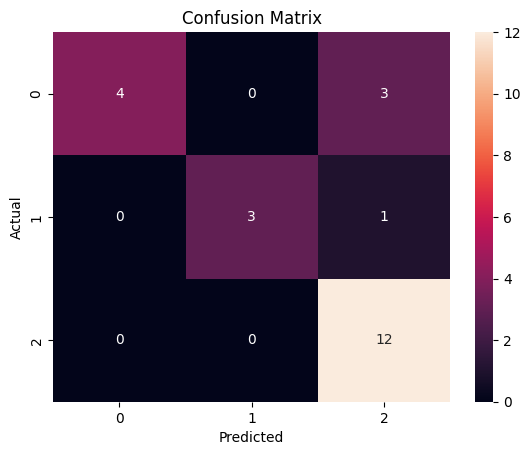

In [131]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

[[ 4  0  3]
 [ 0  3  1]
 [ 0  0 12]]


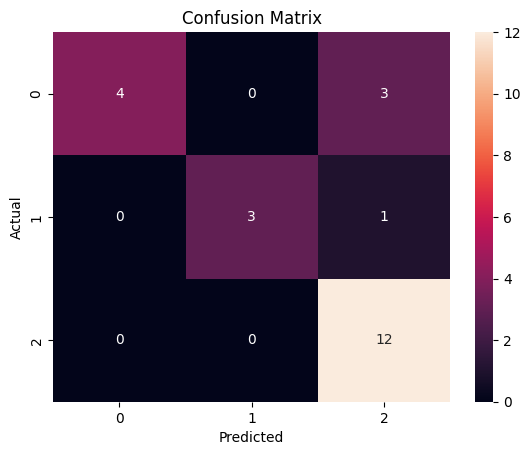

In [132]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [133]:
import joblib

joblib.dump(model, "ticket_classifier_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print(model)
print(vectorizer)

Model saved successfully!
SVC(class_weight='balanced')
TfidfVectorizer(min_df=2, ngram_range=(1, 2), stop_words='english')


In [134]:
import sklearn
print(sklearn.__version__)

1.6.1


In [136]:
from sklearn.base import BaseEstimator
from sklearn.feature_extraction.text import TfidfVectorizer

for name, obj in list(globals().items()):
    if isinstance(obj, TfidfVectorizer):
        print("VECTORIZER:", name)
    elif isinstance(obj, BaseEstimator) and hasattr(obj, "classes_"):
        print("MODEL:", name, type(obj).__name__, list(obj.classes_))

VECTORIZER: vectorizer
MODEL: category_model MultinomialNB [np.str_('Billing'), np.str_('Refund'), np.str_('Shipping'), np.str_('Technical')]
MODEL: priority_model MultinomialNB [np.str_('High'), np.str_('Low'), np.str_('Medium')]
MODEL: model SVC ['High', 'Low', 'Medium']
MODEL: _23 SVC ['High', 'Low', 'Medium']
VECTORIZER: _31
MODEL: _59 SVC ['High', 'Low', 'Medium']
VECTORIZER: _67
MODEL: _95 SVC ['High', 'Low', 'Medium']
MODEL: _116 SVC ['High', 'Low', 'Medium']
MODEL: _120 SVC ['High', 'Low', 'Medium']


In [137]:

# Inspect the machine-learning objects in the notebook

for name, obj in globals().copy().items():
    if name.startswith("__"):
        continue

    obj_type = type(obj).__name__

    if obj_type in ("TfidfVectorizer", "CountVectorizer"):
        print(f"VECTORIZER: {name}")

    elif obj_type in ("SVC", "MultinomialNB", "LogisticRegression",
                      "RandomForestClassifier", "Pipeline"):
        labels = getattr(obj, "classes_", None)
        print(f"MODEL: {name} | Type: {obj_type} | Labels: {labels}")

VECTORIZER: vectorizer
MODEL: category_model | Type: MultinomialNB | Labels: ['Billing' 'Refund' 'Shipping' 'Technical']
MODEL: priority_model | Type: MultinomialNB | Labels: ['High' 'Low' 'Medium']
MODEL: model | Type: SVC | Labels: ['High' 'Low' 'Medium']
MODEL: _23 | Type: SVC | Labels: ['High' 'Low' 'Medium']
VECTORIZER: _31
MODEL: _59 | Type: SVC | Labels: ['High' 'Low' 'Medium']
VECTORIZER: _67
MODEL: _95 | Type: SVC | Labels: ['High' 'Low' 'Medium']
MODEL: _116 | Type: SVC | Labels: ['High' 'Low' 'Medium']
MODEL: _120 | Type: SVC | Labels: ['High' 'Low' 'Medium']


In [138]:

import joblib

for name in ["vectorizer", "_31", "_67"]:
    obj = globals().get(name)

    if obj is not None:
        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "vocabulary_"):
            print("Vocabulary size:", len(obj.vocabulary_))
        else:
            print("Vocabulary not fitted or unavailable")


vectorizer
Type: TfidfVectorizer
Vocabulary size: 107

_31
Type: TfidfVectorizer
Vocabulary not fitted or unavailable

_67
Type: TfidfVectorizer
Vocabulary not fitted or unavailable


In [139]:

for name in ["vectorizer", "category_model", "priority_model",
             "model", "_23", "_59", "_95", "_116", "_120"]:

    obj = globals().get(name)

    if obj is None:
        continue

    print(f"\n{name}: {type(obj).__name__}")

    if hasattr(obj, "n_features_in_"):
        print("Expected input features:", obj.n_features_in_)

    if hasattr(obj, "classes_"):
        print("Labels:", obj.classes_)

    if hasattr(obj, "vocabulary_"):
        print("Vocabulary size:", len(obj.vocabulary_))


vectorizer: TfidfVectorizer
Vocabulary size: 107

category_model: MultinomialNB
Expected input features: 230
Labels: ['Billing' 'Refund' 'Shipping' 'Technical']

priority_model: MultinomialNB
Expected input features: 230
Labels: ['High' 'Low' 'Medium']

model: SVC
Expected input features: 107
Labels: ['High' 'Low' 'Medium']

_23: SVC
Expected input features: 281
Labels: ['High' 'Low' 'Medium']

_59: SVC
Expected input features: 281
Labels: ['High' 'Low' 'Medium']

_95: SVC
Expected input features: 92
Labels: ['High' 'Low' 'Medium']

_116: SVC
Expected input features: 92
Labels: ['High' 'Low' 'Medium']

_120: SVC
Expected input features: 107
Labels: ['High' 'Low' 'Medium']


In [140]:
for i, cell in enumerate(In[1:], start=1):
    if isinstance(cell, str) and any(
        word in cell.lower()
        for word in ["tfidfvectorizer", "fit_transform", "category_model", "priority_model"]
    ):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(cell)


==================== CELL 7 ====================
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['cleaned_text'])

print("Text converted to numbers successfully!")
print("Shape:", X.shape)

==================== CELL 8 ====================
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Our inputs and output
y_category = df['category']

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_category, test_size=0.2, random_state=42
)

# Build and train the model
category_model = MultinomialNB()
category_model.fit(X_train, y_train)

# Test it
y_pred = category_model.predict(X_test)

print("Category Classification Results:")
print(classification_report(y_test, y_pred))

==================== CELL 9 ====================
from sklearn.naive_bayes import MultinomialNB
from skl

In [141]:
for i, cell in enumerate(In):
    if isinstance(cell, str) and any(
        word in cell.lower()
        for word in [
            "tfidfvectorizer",
            "fit_transform",
            "category_model.fit",
            "priority_model.fit",
            "train_test_split"
        ]
    ):
        print(f"\n{'=' * 15} CELL {i} {'=' * 15}")
        print(cell)


=============== CELL 7 ===============
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['cleaned_text'])

print("Text converted to numbers successfully!")
print("Shape:", X.shape)

=============== CELL 8 ===============
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Our inputs and output
y_category = df['category']

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_category, test_size=0.2, random_state=42
)

# Build and train the model
category_model = MultinomialNB()
category_model.fit(X_train, y_train)

# Test it
y_pred = category_model.predict(X_test)

print("Category Classification Results:")
print(classification_report(y_test, y_pred))

=============== CELL 9 ===============
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import tr

In [142]:
print("CATEGORY MODEL")
print("Features:", category_model.n_features_in_)

print("\nPRIORITY MODEL")
print("Features:", priority_model.n_features_in_)

print("\nCURRENT VECTORIZER")
print("Features:", len(vectorizer.vocabulary_))

CATEGORY MODEL
Features: 230

PRIORITY MODEL
Features: 230

CURRENT VECTORIZER
Features: 107


In [143]:
print("Checking the current X variable...")

print("X shape:", X.shape)

print("\nChecking the vectorizer...")
print("Vectorizer vocabulary:", len(vectorizer.vocabulary_))

print("\nChecking the original training data...")
print("Cleaned text column exists:", "cleaned_text" in df.columns)
print("Number of rows:", len(df))

Checking the current X variable...
X shape: (115,)

Checking the vectorizer...
Vectorizer vocabulary: 107

Checking the original training data...
Cleaned text column exists: False
Number of rows: 100


In [144]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset columns:
['ticket_text', 'category', 'priority']

First 5 rows:


,ticket_text,category,priority
0,My account was hacked urgently need help immed...,Technical,High
1,My laptop stopped working I lost all my data e...,Technical,High
2,I cannot login to my account urgent please hel...,Technical,High
3,The website is down urgently cannot place any ...,Technical,High
4,My files got deleted after update need immedia...,Technical,High



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ticket_text  100 non-null    object
 1   category     100 non-null    object
 2   priority     100 non-null    object
dtypes: object(3)
memory usage: 2.5+ KB


In [145]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

# 1. Prepare the ticket text
X_text = df["ticket_text"].fillna("").astype(str)

# 2. Convert ticket text into numerical features
app_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1
)

X_features = app_vectorizer.fit_transform(X_text)

# 3. Split the data for training and testing
X_train, X_test, y_cat_train, y_cat_test, y_pri_train, y_pri_test = (
    train_test_split(
        X_features,
        df["category"],
        df["priority"],
        test_size=0.2,
        random_state=42
    )
)

# 4. Train the category model
app_category_model = MultinomialNB()
app_category_model.fit(X_train, y_cat_train)

# 5. Train the priority model
app_priority_model = MultinomialNB()
app_priority_model.fit(X_train, y_pri_train)

# 6. Check the results
print("CATEGORY MODEL")
print(classification_report(
    y_cat_test,
    app_category_model.predict(X_test),
    zero_division=0
))

print("\nPRIORITY MODEL")
print(classification_report(
    y_pri_test,
    app_priority_model.predict(X_test),
    zero_division=0
))

# 7. Confirm that the feature counts match
print("\nVectorizer features:", len(app_vectorizer.vocabulary_))
print("Category model features:", app_category_model.n_features_in_)
print("Priority model features:", app_priority_model.n_features_in_)

CATEGORY MODEL
              precision    recall  f1-score   support

     Billing       1.00      0.29      0.44         7
      Refund       0.50      0.75      0.60         4
    Shipping       0.00      0.00      0.00         3
   Technical       0.50      1.00      0.67         6

    accuracy                           0.55        20
   macro avg       0.50      0.51      0.43        20
weighted avg       0.60      0.55      0.48        20


PRIORITY MODEL
              precision    recall  f1-score   support

        High       1.00      0.14      0.25         7
         Low       0.00      0.00      0.00         3
      Medium       0.53      1.00      0.69        10

    accuracy                           0.55        20
   macro avg       0.51      0.38      0.31        20
weighted avg       0.61      0.55      0.43        20


Vectorizer features: 548
Category model features: 548
Priority model features: 548


In [146]:
import joblib

joblib.dump(app_vectorizer, "tfidf_vectorizer.pkl")
joblib.dump(app_category_model, "ticket_classifier_model.pkl")
joblib.dump(app_priority_model, "ticket_priority_model.pkl")

print("All three files saved successfully!")

import os

for filename in [
    "tfidf_vectorizer.pkl",
    "ticket_classifier_model.pkl",
    "ticket_priority_model.pkl"
]:
    print(filename, "->", os.path.abspath(filename))

All three files saved successfully!
tfidf_vectorizer.pkl -> /content/tfidf_vectorizer.pkl
ticket_classifier_model.pkl -> /content/ticket_classifier_model.pkl
ticket_priority_model.pkl -> /content/ticket_priority_model.pkl
